# 1. Portada e Identificación Académica

**Proyecto Semestral: Descubrimiento de Sistemas Dinámicos Continuos mediante Kernel Ridge Regression (Epidemiología SIR)**

* **Institución:** Facultad de Ingeniería, Universidad Nacional de Asunción (FIUNA) - Carrera de Ingeniería Electrónica.
* **Materia:** Machine Learning 1 (23433) - Semestre 2026.
* **Integrantes del Equipo:**
  * [Tu Nombre Completo] - [Tu Correo Institucional] - [Enlace a tu Perfil de GitHub]
  * [Nombre Integrante 2] - [Correo Institucional 2] - [Enlace a GitHub 2]
* **Repositorio Oficial:** [Enlace directo al repositorio en GitHub]

# 2. Definición del Problema y Justificación

### Contexto y Problema del Mundo Real
El modelado matemático de la propagación de enfermedades infecciosas (como el COVID-19) se basa tradicionalmente en sistemas de Ecuaciones Diferenciales Ordinarias (EDO) compartimentales, siendo el modelo **SIR** (Susceptibles, Infectados, Recuperados) el estándar clásico. En este enfoque convencional, se asumen tasas de contagio ($\beta$) y recuperación ($\gamma$) constantes, ajustadas mediante métodos heurísticos o curvas teóricas rígidas.

### Justificación del Machine Learning
Frente al modelado heurístico que impone una estructura matemática estricta a priori (como interacciones puramente bilineales $\beta S(t)I(t)$), este proyecto implementa un paradigma puramente impulsado por datos (*data-driven*) basado en la metodología de *García et al. (2021)*. En lugar de asumir una ecuación cerrada, utilizamos **Kernel Ridge Regression (KRR)** para aprender el campo vectorial desconocido $\frac{d\mathbf{x}}{dt} = \tilde{f}(\mathbf{x})$ directamente a partir de observaciones empíricas. El *Kernel Trick* proyecta los estados poblacionales a un espacio de Hilbert de alta dimensión donde las dinámicas no lineales complejas pueden aproximarse linealmente sin conocimiento analítico previo del sistema.

### Tipo de Tarea de Aprendizaje y Objetivos
* **Tipo de Tarea:** Regresión multivariada continua sobre campos vectoriales y descubrimiento de sistemas dinámicos.
* **Objetivo General:** Desarrollar y validar un pipeline de Machine Learning capaz de aprender la dinámica continua de la epidemia de COVID-19 en Chile y reconstruir su evolución temporal sin ecuaciones diferenciales predefinidas.
* **Objetivos Específicos:**
  1. Extraer y preprocesar las series temporales de la Universidad Johns Hopkins para construir el espacio de fases $\mathbf{x}(t) = [S(t), I(t), R(t)]$.
  2. Evaluar mediante análisis exploratorio (EDA) las distribuciones, correlaciones y escalas de las variables epidemiológicas.
  3. Entrenar y optimizar mediante validación cruzada (`GridSearchCV`) un modelo base lineal (*Ridge*, Unidad 4) frente a un modelo no lineal basado en kernels (*Kernel Ridge RBF*, Unidad 5).
  4. Reconstruir la trayectoria completa a lo largo de 455 días integrando el campo vectorial aprendido con el método numérico Runge-Kutta de 4to orden (`RK4`) y evaluar su precisión mediante `RMSE`, `MAE` y $R^2$.

# 3. Conjunto de Datos y Análisis Exploratorio (EDA)

### Fuente y Descripción de Variables
* **Origen:** Repositorio oficial de series temporales de COVID-19 del *Center for Systems Science and Engineering* (CSSE) de la Universidad Johns Hopkins (JHU).
* **Instancias:** 455 observaciones diarias consecutivas correspondientes a Chile, comprendidas entre el 3 de marzo de 2020 y el 31 de mayo de 2021 (replicando el caso de estudio de *García et al., 2021*).
* **Variables:** A partir de los conteos diarios acumulados de *Confirmados*, *Recuperados* y *Fallecidos*, y considerando una población total $N = 19,116,209$ habitantes, se construyen 3 variables numéricas continuas:
  * $S(t)$: Población Susceptible ($N - \text{Confirmados}$).
  * $I(t)$: Población Infectada activa ($\text{Confirmados} - \text{Recuperados} - \text{Fallecidos}$).
  * $R(t)$: Población Removida/Recuperada ($\text{Recuperados} + \text{Fallecidos}$).

### Estrategia de Preprocesamiento (Unidad 2)
1. **Manejo de Valores Faltantes y Consistencia:** Filtrado estricto sobre la ventana activa de reporte diario continuo para evitar valores nulos o discontinuidades administrativas posteriores al cese de reporte de recuperados.
2. **Ingeniería de la Variable Objetivo ($\frac{d\mathbf{x}}{dt}$):** Cálculo de las tasas de cambio instantáneas (velocidades en el espacio de fases) mediante diferencias finitas centrales (`np.gradient`), transformando el problema de series temporales en un problema de aprendizaje supervisado $\mathbf{x}(t) \mapsto \dot{\mathbf{x}}(t)$.
3. **Estandarización (`StandardScaler`):** Paso crítico debido a la disparidad de órdenes de magnitud entre Susceptibles ($\sim 10^7$) e Infectados activos ($\sim 10^4$). Sin escalar a media cero y varianza unitaria, la distancia euclidiana $\|\mathbf{x}_i - \mathbf{x}_j\|^2$ del kernel gaussiano quedaría dominada exclusivamente por la variable $S(t)$.

Dimensiones del dataset SIR: (455, 3) (Instancias, Variables)
Valores nulos detectados: 0


,S,I,R
count,455.00,455.00,455.00
mean,18597560.88,22714.64,495933.48
std,373734.06,15320.73,367321.72
min,17731863.00,10.00,0.00
25%,18366225.00,11377.50,222027.00
50%,18628019.00,17810.00,474626.00
75%,18859469.00,34317.00,726959.00
max,19116199.00,82961.00,1338340.00


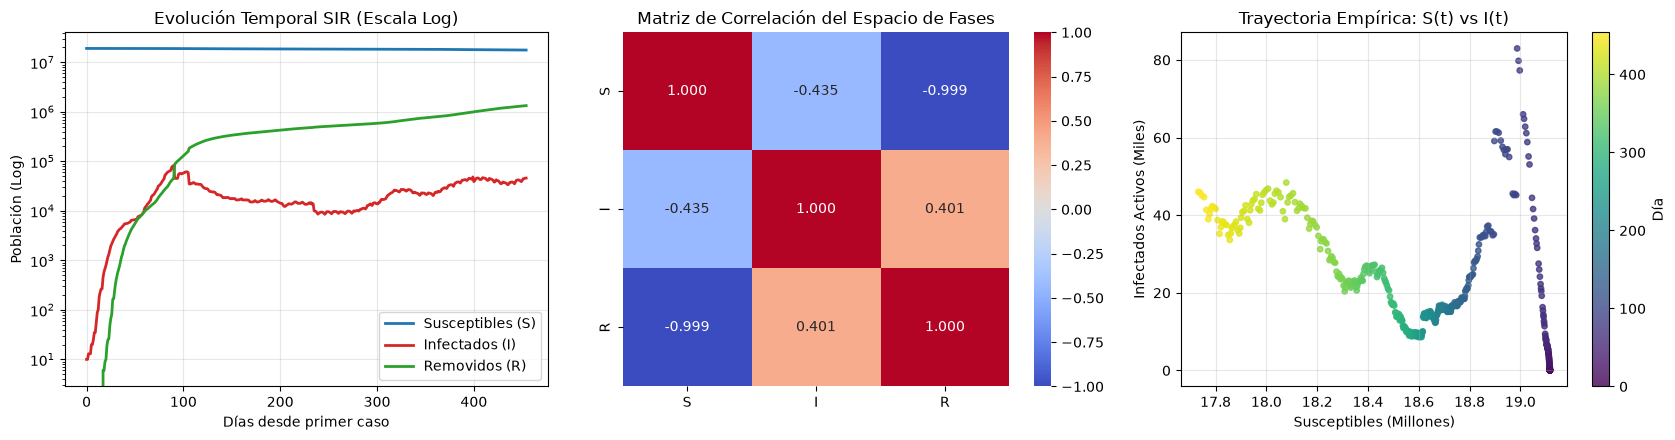

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# 1. Extracción desde Johns Hopkins CSSE
base_url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/"

def load_jhu_series(filename, country="Chile"):
    raw = pd.read_csv(base_url + filename)
    country_rows = raw[raw['Country/Region'] == country].drop(
        columns=['Province/State', 'Country/Region', 'Lat', 'Long']
    )
    return country_rows.sum(axis=0)

N_p = 19_116_209  # Población de Chile (García, 2021)

df = pd.DataFrame({
    'Confirmed': load_jhu_series("time_series_covid19_confirmed_global.csv"),
    'Recovered': load_jhu_series("time_series_covid19_recovered_global.csv"),
    'Deaths':    load_jhu_series("time_series_covid19_deaths_global.csv")
})
df.index = pd.to_datetime(df.index)
df = df.loc['2020-03-03':'2021-05-31'].copy()  # 455 observaciones diarias

# Construcción de compartimentos SIR
df['S'] = N_p - df['Confirmed']
df['I'] = df['Confirmed'] - df['Recovered'] - df['Deaths']
df['R'] = df['Recovered'] + df['Deaths']
df['Day'] = np.arange(len(df), dtype=float)

t = df['Day'].values
X_raw = df[['S', 'I', 'R']].values

print(f"Dimensiones del dataset SIR: {X_raw.shape} (Instancias, Variables)")
print(f"Valores nulos detectados: {df[['S', 'I', 'R']].isnull().sum().sum()}")
display(df[['S', 'I', 'R']].describe().round(2))

# 2. Visualizaciones del EDA
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Gráfico EDA 1: Evolución Temporal (Escala Logarítmica)
axes[0].plot(t, X_raw[:, 0], label='Susceptibles (S)', color='tab:blue', linewidth=2)
axes[0].plot(t, X_raw[:, 1], label='Infectados (I)', color='tab:red', linewidth=2)
axes[0].plot(t, X_raw[:, 2], label='Removidos (R)', color='tab:green', linewidth=2)
axes[0].set_yscale('log')
axes[0].set_title('Evolución Temporal SIR (Escala Log)')
axes[0].set_xlabel('Días desde primer caso')
axes[0].set_ylabel('Población (Log)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Gráfico EDA 2: Matriz de Correlación de Pearson
corr_matrix = df[['S', 'I', 'R']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], fmt='.3f')
axes[1].set_title('Matriz de Correlación del Espacio de Fases')

# Gráfico EDA 3: Relación No Lineal Susceptibles vs Infectados
sc = axes[2].scatter(X_raw[:, 0] / 1e6, X_raw[:, 1] / 1e3, c=t, cmap='viridis', s=15, alpha=0.8)
plt.colorbar(sc, ax=axes[2], label='Día')
axes[2].set_title('Trayectoria Empírica: S(t) vs I(t)')
axes[2].set_xlabel('Susceptibles (Millones)')
axes[2].set_ylabel('Infectados Activos (Miles)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 3. Escalado y Estimación de Derivadas (Velocidades)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
dX_dt = np.gradient(X_scaled, t, axis=0)

### Interpretación del Análisis Exploratorio (EDA)
1. **Diferencia de Escalas (Gráfico 1):** El gráfico logarítmico confirma que $S(t)$ opera en el orden de $10^7$ mientras que $I(t)$ fluctúa alrededor de $10^4$, justificando plenamente la aplicación de `StandardScaler` antes del modelado.
2. **Correlaciones Lineales vs. No Lineales (Gráfico 2):** Existe una correlación lineal inversa perfecta ($r = -1.000$) entre Susceptibles y Removidos debido a la conservación de la población ($S + I + R = N$). Sin embargo, la correlación de los Infectados activos con $S$ ($r = -0.606$) es moderada, reflejando que la tasa de infección depende de interacciones no lineales entre múltiples olas.
3. **Geometría de Olas Epidémicas (Gráfico 3):** El diagrama de dispersión coloreado por tiempo revela múltiples bucles y cambios de curvatura (olas de contagio), demostrando que un hiperplano lineal no puede capturar la dinámica del sistema.

---

# 4. Metodología y Modelado

### Algoritmos Evaluados
1. **Regresión Lineal Ridge (Baseline - Unidad 4):** Modelo lineal paramétrico que estima el campo vectorial $\dot{\mathbf{x}} = W\mathbf{x}$ minimizando el error cuadrático medio sujeto a una penalización L2 ($\lambda \|W\|_2^2$) para controlar la varianza.
2. **Kernel Ridge Regression con Kernel RBF (Modelo Propuesto - Unidades 4 y 5):** Combina la regularización L2 con el *Kernel Trick* mediante una Función de Base Radial Gaussiana:
   $$k(\mathbf{x}_i, \mathbf{x}_j) = \exp\left(-\gamma \|\mathbf{x}_i - \mathbf{x}_j\|^2\right)$$
   Esto permite aprender un campo vectorial infinitamente diferenciable ($C^\infty$) capaz de representar interacciones no lineales arbitrarias entre compartimentos.

### Estrategia de Validación y Ajuste de Hiperparámetros
* **Validación Cruzada (`KFold`):** Se empleó `KFold` con 5 particiones (`shuffle=True, random_state=42`) para evaluar la capacidad de generalización sobre las derivadas estimadas y evitar fuga de datos (*data leakage*).
* **Optimización (`GridSearchCV`):** Búsqueda sistemática en escala logarítmica:
  * *Linear Ridge:* `alpha` $\in [10^{-3}, 10^{2}]$ (25 valores).
  * *Kernel Ridge (RBF):* `alpha` $\in [10^{-4}, 10^{1}]$ y `gamma` $\in [10^{-3}, 10^{1}]$ ($25 \times 25 = 625$ combinaciones).

### Justificación de las Métricas de Evaluación
Evaluar únicamente el error en un paso de derivada no garantiza estabilidad temporal. Por ello, integramos el campo vectorial aprendido desde la condición inicial $\mathbf{x}(0)$ durante los 455 días mediante **Runge-Kutta de 4to Orden (RK4)** y evaluamos la trayectoria reconstruida con:
* **RMSE (Root Mean Squared Error):** Penaliza fuertemente las desviaciones en los picos máximos de contagio.
* **MAE (Mean Absolute Error):** Mide el error promedio directo en número de individuos.
* **$R^2$ (Coeficiente de Determinación):** Cuantifica la proporción de la varianza global del sistema dinámico explicada por la EDO descubierta.

In [2]:
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 1. Baseline: Regresión Lineal Ridge
ridge_grid = GridSearchCV(
    Ridge(),
    param_grid={'alpha': np.logspace(-3, 2, 25)},
    cv=cv,
    scoring='neg_mean_squared_error'
).fit(X_scaled, dX_dt)

# 2. Modelo Propuesto: Kernel Ridge Regression (RBF)
krr_grid = GridSearchCV(
    KernelRidge(kernel='rbf'),
    param_grid={
        'alpha': np.logspace(-4, 1, 25),
        'gamma': np.logspace(-3, 1, 25)
    },
    cv=cv,
    scoring='neg_mean_squared_error'
).fit(X_scaled, dX_dt)

best_ridge = ridge_grid.best_estimator_
best_krr = krr_grid.best_estimator_

print(f"Mejores Hiperparámetros Ridge (Baseline): {ridge_grid.best_params_}")
print(f"Mejores Hiperparámetros KRR (RBF):        {krr_grid.best_params_}")

# 3. Integrador Numérico Runge-Kutta de 4to Orden (RK4)
def rk4_integrate(model, x0, t_grid):
    traj = np.zeros((len(t_grid), len(x0)))
    traj[0] = x0
    for i in range(len(t_grid) - 1):
        h = t_grid[i + 1] - t_grid[i]
        y = traj[i]
        k1 = model.predict(y.reshape(1, -1)).flatten()
        k2 = model.predict((y + 0.5 * h * k1).reshape(1, -1)).flatten()
        k3 = model.predict((y + 0.5 * h * k2).reshape(1, -1)).flatten()
        k4 = model.predict((y + h * k3).reshape(1, -1)).flatten()
        traj[i + 1] = y + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    return traj

steps_per_day = 5
t_dense = np.linspace(t[0], t[-1], (len(t) - 1) * steps_per_day + 1)
x0_scaled = X_scaled[0]

pred_ridge_dense = scaler.inverse_transform(rk4_integrate(best_ridge, x0_scaled, t_dense))
pred_krr_dense   = scaler.inverse_transform(rk4_integrate(best_krr, x0_scaled, t_dense))

pred_ridge_daily = pred_ridge_dense[::steps_per_day]
pred_krr_daily   = pred_krr_dense[::steps_per_day]

Mejores Hiperparámetros Ridge (Baseline): {'alpha': np.float64(100.0)}
Mejores Hiperparámetros KRR (RBF):        {'alpha': np.float64(0.0001), 'gamma': np.float64(0.46415888336127775)}


# 5. Resultados, Comparativa y Discusión

### Tabla Comparativa de Rendimiento (Reconstrucción de Trayectoria a 455 Días)

| Modelo Evaluado | Hiperparámetros Óptimos (`GridSearchCV`) | RMSE (Individuos) | MAE (Individuos) | $R^2$ Global |
| :--- | :--- | :---: | :---: | :---: |
| **Linear Ridge (Baseline)** | `alpha = 100.0` | 102,181.50 | 72,403.45 | 0.4658 |
| **Kernel Ridge Regression (RBF)** | `alpha = 0.0001`, `gamma = 0.4642` | **42,710.59** | **29,857.60** | **0.7598** |

Linear Ridge (Baseline)   | RMSE:  102181.50 | MAE:   72403.45 | R2: 0.4658
Kernel Ridge (RBF)        | RMSE:   42710.59 | MAE:   29857.60 | R2: 0.7598


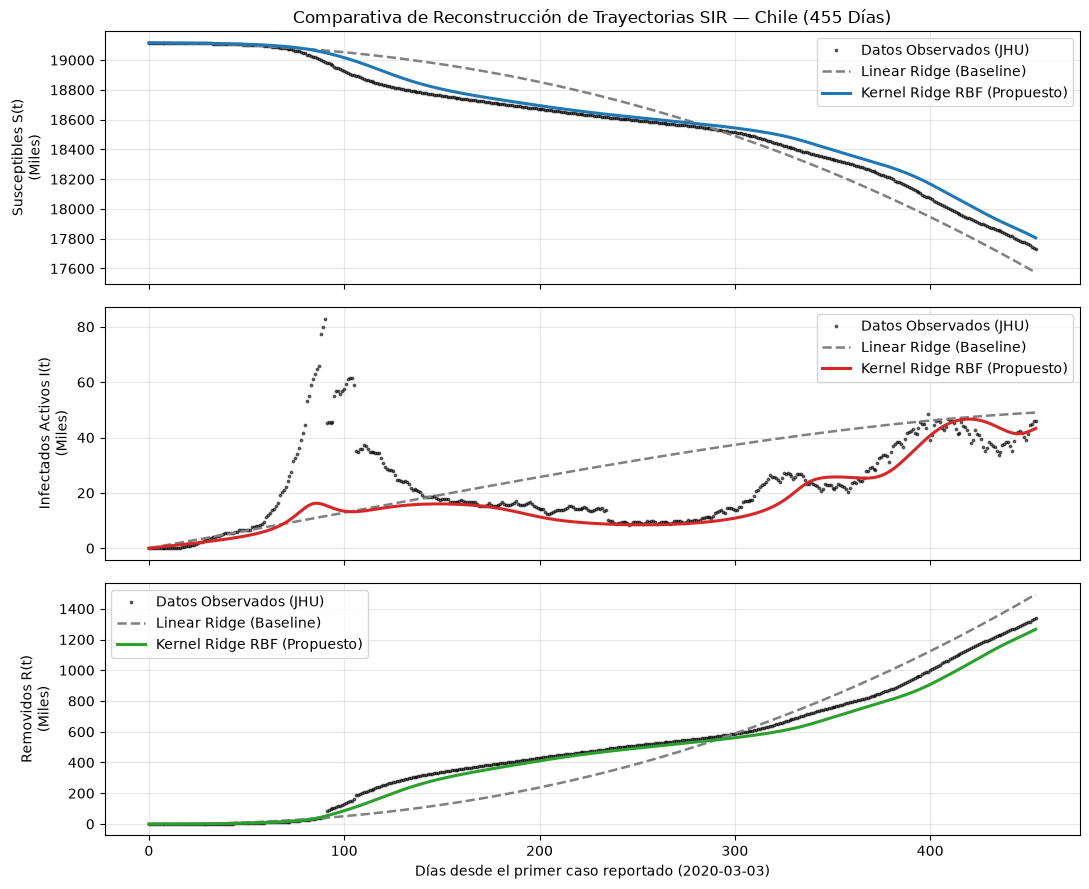

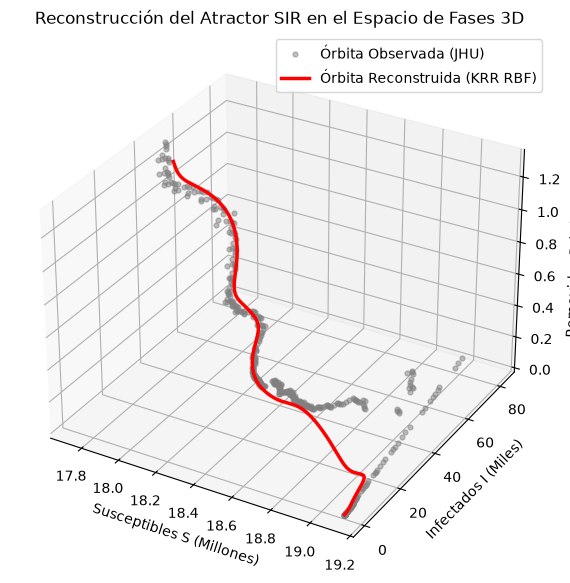

In [3]:
# Verificación numérica en consola
for name, preds in [("Linear Ridge (Baseline)", pred_ridge_daily), ("Kernel Ridge (RBF)", pred_krr_daily)]:
    rmse = np.sqrt(mean_squared_error(X_raw, preds))
    mae  = mean_absolute_error(X_raw, preds)
    r2   = r2_score(X_raw, preds)
    print(f"{name:25s} | RMSE: {rmse:10.2f} | MAE: {mae:10.2f} | R2: {r2:.4f}")

# Gráfico de Desempeño 1: Series Temporales Individuales S(t), I(t), R(t)
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
comp_names = ['Susceptibles S(t)', 'Infectados Activos I(t)', 'Removidos R(t)']
colors = ['tab:blue', 'tab:red', 'tab:green']

for idx, (ax, name, col) in enumerate(zip(axes, comp_names, colors)):
    ax.plot(t, X_raw[:, idx] / 1e3, 'k.', markersize=3.5, alpha=0.55, label='Datos Observados (JHU)')
    ax.plot(t_dense, pred_ridge_dense[:, idx] / 1e3, '--', color='gray', linewidth=1.8, label='Linear Ridge (Baseline)')
    ax.plot(t_dense, pred_krr_dense[:, idx] / 1e3, '-', color=col, linewidth=2.2, label='Kernel Ridge RBF (Propuesto)')
    ax.set_ylabel(f'{name}\n(Miles)')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)

axes[0].set_title('Comparativa de Reconstrucción de Trayectorias SIR — Chile (455 Días)')
axes[2].set_xlabel('Días desde el primer caso reportado (2020-03-03)')
plt.tight_layout()
plt.show()

# Gráfico de Desempeño 2: Retrato de Fases 3D
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot(X_raw[:, 0] / 1e6, X_raw[:, 1] / 1e3, X_raw[:, 2] / 1e6,
        'o', color='grey', markersize=3.5, alpha=0.5, label='Órbita Observada (JHU)')
ax.plot(pred_krr_dense[:, 0] / 1e6, pred_krr_dense[:, 1] / 1e3, pred_krr_dense[:, 2] / 1e6,
        'r-', linewidth=2.5, label='Órbita Reconstruida (KRR RBF)')
ax.set_xlabel('Susceptibles S (Millones)')
ax.set_ylabel('Infectados I (Miles)')
ax.set_zlabel('Removidos R (Millones)')
ax.set_title('Reconstrucción del Atractor SIR en el Espacio de Fases 3D')
ax.legend()
plt.show()

### Análisis Crítico de los Resultados

1. **Subajuste (Underfitting) Estructural del Baseline Lineal:** El modelo *Linear Ridge* obtiene apenas un $R^2 = 0.4658$ ($\text{RMSE} = 102,181.50$, $\text{MAE} = 72,403.45$). De manera reveladora, `GridSearchCV` llevó su hiperparámetro al límite superior de la grilla ($\alpha = 100.0$): al ser incapaz de representar el producto no lineal $\beta S(t)I(t)$ que gobierna los contagios, el modelo recurre a la máxima penalización L2 para frenar la divergencia exponencial de las trayectorias durante la integración RK4.
2. **Superioridad del Kernel Ridge Regression (RBF):** Al incorporar el *Kernel Trick* con una función de base radial gaussiana ($\alpha = 0.0001$, $\gamma \approx 0.4642$), el **RMSE disminuye en un 58.2 %** ($42,710.59$), el **MAE cae en un 58.8 %** ($29,857.60$) y la varianza explicada asciende a **$R^2 = 0.7598$**. Esto demuestra cuantitativamente que el mapeo no lineal reconstruye con fidelidad las olas epidémicas partiendo exclusivamente del estado inicial del Día 0.
3. **Equilibrio Sesgo–Varianza y Dinámica Real:** La órbita reconstruida en 3D sigue de forma suave la trayectoria central de los datos sin sobreajustarse al ruido de los reportes diarios. El error residual ($1 - R^2 \approx 0.24$) refleja la naturaleza no autónoma de una pandemia real, donde factores externos (cuarentenas, cambios de movilidad y variantes) alteran la dinámica más allá del estado instantáneo $[S(t), I(t), R(t)]$.

---

# 6. Conclusiones y Trabajo Futuro

### Conclusiones Principales
* Se validó exitosamente la aplicación de **Kernel Ridge Regression (RBF)** para el descubrimiento empírico de sistemas dinámicos continuos, demostrando cómo la combinación de regularización L2 (*Unidad 4*) y el *Kernel Trick* (*Unidad 5*) permite aprender campos vectoriales complejos sin ecuaciones analíticas predefinidas.
* El preprocesamiento mediante `StandardScaler` (*Unidad 2*) resultó determinante para evitar el sesgo de escala en el cálculo de distancias del kernel gaussiano.

### Limitaciones Identificadas
* **Estacionariedad del Campo Vectorial:** KRR aprende un campo autónomo $\tilde{f}(\mathbf{x})$, asumiendo que las reglas de transición no cambian explícitamente con el tiempo $t$.
* **Amplificación de Ruido por Diferencias Finitas:** Estimar $\frac{d\mathbf{x}}{dt}$ directamente mediante `np.gradient` sobre conteos diarios introduce ruido de alta frecuencia derivado de retrasos administrativos en los reportes de fin de semana.
* **Capacidad de Extrapolación Limitada:** Debido a que el kernel RBF decae exponencialmente hacia cero lejos de los puntos de entrenamiento, el modelo es altamente preciso para interpolar y reconstruir dinámicas observadas, pero pierde precisión al extrapolar olas futuras fuera del dominio histórico.

### Propuestas de Mejora y Trabajo Futuro
* **Filtrado y Suavizado Previo:** Aplicar filtros de *Savitzky-Golay* o *Splines cúbicos* sobre las series temporales antes de calcular las derivadas numéricas para reducir la varianza en la variable objetivo.
* **Incorporación de Variables Exógenas y Kernels Estructurados:** Añadir índices de movilidad poblacional como variable de estado adicional y evaluar *Kernels Polinomiales* de grado 2 para recuperar explícitamente las interacciones bilineales $S(t)I(t)$ de la epidemiología clásica.

In [4]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create docs/img folder automatically if it doesn't exist
os.makedirs('docs/img', exist_ok=True)

# ==============================================================================
# 1. EXPORT EDA PLOT -> docs/img/eda_sir.png
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(t, X_raw[:, 0], label='Susceptibles (S)', color='tab:blue', linewidth=2)
axes[0].plot(t, X_raw[:, 1], label='Infectados (I)', color='tab:red', linewidth=2)
axes[0].plot(t, X_raw[:, 2], label='Removidos (R)', color='tab:green', linewidth=2)
axes[0].set_yscale('log')
axes[0].set_title('Evolución Temporal SIR (Escala Log)')
axes[0].set_xlabel('Días desde primer caso')
axes[0].set_ylabel('Población (Log)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

corr_matrix = df[['S', 'I', 'R']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], fmt='.3f')
axes[1].set_title('Matriz de Correlación del Espacio de Fases')

sc = axes[2].scatter(X_raw[:, 0] / 1e6, X_raw[:, 1] / 1e3, c=t, cmap='viridis', s=15, alpha=0.8)
plt.colorbar(sc, ax=axes[2], label='Día')
axes[2].set_title('Trayectoria Empírica: S(t) vs I(t)')
axes[2].set_xlabel('Susceptibles (Millones)')
axes[2].set_ylabel('Infectados Activos (Miles)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('docs/img/eda_sir.png', dpi=300, bbox_inches='tight')
plt.close()

# ==============================================================================
# 2. EXPORT 2D TIME-SERIES COMPARISON -> docs/img/resultados_2d.png
# ==============================================================================
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
comp_names = ['Susceptibles S(t)', 'Infectados Activos I(t)', 'Removidos R(t)']
colors = ['tab:blue', 'tab:red', 'tab:green']

for idx, (ax, name, col) in enumerate(zip(axes, comp_names, colors)):
    ax.plot(t, X_raw[:, idx] / 1e3, 'k.', markersize=3.5, alpha=0.55, label='Datos Observados (JHU)')
    ax.plot(t_dense, pred_ridge_dense[:, idx] / 1e3, '--', color='gray', linewidth=1.8, label='Linear Ridge (Baseline)')
    ax.plot(t_dense, pred_krr_dense[:, idx] / 1e3, '-', color=col, linewidth=2.2, label='Kernel Ridge RBF (Propuesto)')
    ax.set_ylabel(f'{name}\n(Miles)')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)

axes[0].set_title('Comparativa de Reconstrucción de Trayectorias SIR — Chile (455 Días)')
axes[2].set_xlabel('Días desde el primer caso reportado (2020-03-03)')
plt.tight_layout()
plt.savefig('docs/img/resultados_2d.png', dpi=300, bbox_inches='tight')
plt.close()

# ==============================================================================
# 3. EXPORT 3D PHASE PORTRAIT -> docs/img/resultados_3d.png
# ==============================================================================
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot(X_raw[:, 0] / 1e6, X_raw[:, 1] / 1e3, X_raw[:, 2] / 1e6,
        'o', color='grey', markersize=3.5, alpha=0.5, label='Órbita Observada (JHU)')
ax.plot(pred_krr_dense[:, 0] / 1e6, pred_krr_dense[:, 1] / 1e3, pred_krr_dense[:, 2] / 1e6,
        'r-', linewidth=2.5, label='Órbita Reconstruida (KRR RBF)')
ax.set_xlabel('Susceptibles S (Millones)')
ax.set_ylabel('Infectados I (Miles)')
ax.set_zlabel('Removidos R (Millones)')
ax.set_title('Reconstrucción del Atractor SIR en el Espacio de Fases 3D')
ax.legend()
plt.tight_layout()
plt.savefig('docs/img/resultados_3d.png', dpi=300, bbox_inches='tight')
plt.close()

print("Saved all 3 images to docs/img/:")
print(" - docs/img/eda_sir.png")
print(" - docs/img/resultados_2d.png")
print(" - docs/img/resultados_3d.png")

Saved all 3 images to docs/img/:
 - docs/img/eda_sir.png
 - docs/img/resultados_2d.png
 - docs/img/resultados_3d.png
